**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: ARAH ROJAS BLANCO
*   MATRÍCULA: A00834299

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [16]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [17]:
loan_df = pd.read_csv('personal_loan.csv', index_col='ID')
n_inicial = len(loan_df)
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


El dataframe inicial contiene 5,037 registros y 13 columnas: 8 numéricas y 5 de texto. Las numéricas son 6 de tipo int64 y 2 de tipo float64. No hay valores faltantes.

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [18]:
loan_df.describe()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000
mean,45.411356,20.122494,73.898352,93152.865595,2.394679,1.942404,1.880941,56.500695
std,11.646805,11.461278,46.130504,2119.637960,1.151145,1.755954,0.843337,101.657580
min,23.000000,-3.000000,8.000000,9307.000000,-3.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,144.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,7.300000,635.000000


In [19]:
loan_df[loan_df['Age'] > 100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


Se eliminan 3 registros con edades de 123, 144 y 130 años (ID 10, 250 y 4800). Se consideran errores de captura por ser edades irreales en estos registros. No se reemplazan porque no conocemos las edades correctas.

In [20]:
loan_df = loan_df[loan_df['Age'] <= 100]
loan_df = loan_df[loan_df['Experience'] >= 0]
loan_df = loan_df[loan_df['Family'] >= 1]
loan_df = loan_df[loan_df['Education'].isin([1, 2, 3])]
loan_df = loan_df[loan_df['ZIP Code'].between(10000, 99999)].copy()

Justificación:

- **Experience:** Los años trabajados no pueden ser negativos.
- **Family:** El tamaño de una familia debe ser un entero positivo.
- **Education:** 1 registro tiene el valor 7.3. Sólo se permiten las categorías 1, 2 y 3.
- **ZIP Code:** Se adopta el formato de cinco dígitos.

`Income`, `CCAvg` y `Mortgage` no presentan valores negativos. Los ceros de gasto o hipoteca son posibles y se conservan. Tampoco hay experiencia mayor que la edad. Los valores monetarios altos no se eliminan sólo por ser extremos, pues no hay evidencia de que sean incorrectos.

In [21]:
restantes = len(loan_df)
eliminados = n_inicial - restantes
porcentaje = eliminados / n_inicial * 100

print('Registros eliminados:', eliminados)
print('Porcentaje eliminado:', round(porcentaje, 2), '%')
print('Registros restantes:', restantes)

Registros eliminados: 60
Porcentaje eliminado: 1.19 %
Registros restantes: 4977


Se eliminaron 60 registros, equivalentes al 1.19 % de los 5,037 iniciales. Quedan 4,977 registros. Este conteo corresponde a la limpieza de valores inválidos.

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [22]:
loan_df.describe(include=object)

,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4977,4977,4977,4977,4977
unique,4,4,4,4,4
top,0,No,No,Yes,0
freq,3475,2693,2462,1700,2628


In [23]:
bin_cols = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']

for columna in bin_cols:
    print('Frecuencias de', columna)
    display(loan_df[columna].value_counts())

Frecuencias de Personal Loan


,count
Personal Loan,
0,3475
No,1017
Yes,368
1,117


Frecuencias de Securities Account


,count
Securities Account,
No,2693
0,1765
Yes,390
1,129


Frecuencias de CD Account


,count
CD Account,
No,2462
0,2212
1,163
Yes,140


Frecuencias de Online


,count
Online,
Yes,1700
No,1628
1,1275
0,374


Frecuencias de CreditCard


,count
CreditCard,
0,2628
Yes,907
No,885
1,557


Cada columna de texto tiene cuatro representaciones: 0, 1, No y Yes. Se unifican como 0 = no y 1 = sí, en Personal Loan, 1 significa que el cliente aceptó el préstamo.

In [24]:
#Se sustituyen los valores
valores_binarios = {'0': 0, 'No': 0, '1': 1, 'Yes': 1}

for columna in bin_cols:
    loan_df[columna] = loan_df[columna].map(valores_binarios)

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [25]:
duplicados = loan_df.duplicated().sum()
loan_df = loan_df.drop_duplicates()
loan_df = loan_df.reset_index(drop=True)

total_eliminados = n_inicial - len(loan_df)
porcentaje_total = total_eliminados / n_inicial * 100

print('Duplicados eliminados:', duplicados)
print('Registros finales:', len(loan_df))
print('Total eliminado desde el inicio:', total_eliminados)
print('Porcentaje total eliminado:', round(porcentaje_total, 2), '%')

Duplicados eliminados: 36
Registros finales: 4941
Total eliminado desde el inicio: 96
Porcentaje total eliminado: 1.91 %


Se detectaron y eliminaron 36 duplicados, comparando todas las columnas sin considerar el antiguo índice ID. El dataframe queda con 4,941 registros. En total se eliminaron 96 registros (1.91 %) respecto al archivo inicial.

5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [26]:
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype(object)
loan_df['Education'] = pd.Categorical(loan_df['Education'],
                                     categories=[1, 2, 3], ordered=True)

for columna in bin_cols:
    loan_df[columna] = loan_df[columna].astype('category')

num_cols = loan_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = loan_df.select_dtypes(include=['object', 'category']).columns.tolist()
print('Variables numéricas:', num_cols)
print('Variables categóricas:', cat_cols)

Variables numéricas: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
Variables categóricas: ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


Quedan **6 variables numéricas** (`Age`, `Experience`, `Income`, `Family`, `CCAvg`, `Mortgage`) y **7 categóricas** (`ZIP Code`, `Education` y las cinco binarias).

`Age` y `Experience` se registran en años completos y `Family` es un conteo, por lo que son discretas. `Income`, `CCAvg` y `Mortgage` representan cantidades monetarias y se analizan como continuas, aunque algunas estén registradas como enteros. `ZIP Code` es nominal, `Education` es ordinal y los cinco indicadores son binarios.


# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [27]:
# .T organiza la tabla con una fila por variable.
estadisticas = loan_df[num_cols].describe().T
estadisticas['asimetría'] = loan_df[num_cols].skew()
estadisticas['curtosis'] = loan_df[num_cols].kurt()
estadisticas

,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis
Age,4941.0,45.560210,11.315617,24.0,36.0,46.0,55.0,67.0,-0.022754,-1.161599
Experience,4941.0,20.335357,11.308351,0.0,11.0,20.0,30.0,43.0,-0.015216,-1.134857
Income,4941.0,73.826553,46.106768,8.0,39.0,64.0,98.0,224.0,0.841991,-0.046164
Family,4941.0,2.391621,1.148244,1.0,1.0,2.0,3.0,4.0,0.159463,-1.403842
CCAvg,4941.0,1.935855,1.748406,0.0,0.7,1.5,2.6,10.0,1.594670,2.635545
Mortgage,4941.0,56.663631,101.875349,0.0,0.0,0.0,101.0,635.0,2.103865,4.760021


Pandas calcula el **exceso de curtosis**: la distribución normal tiene valor 0, los valores negativos corresponden a distribuciones platicúrticas y los positivos a leptocúrticas. Para describir la asimetría se usa como orientación: |asimetría| < 0.5, aproximadamente simétrica; entre 0.5 y 1, moderada; mayor que 1, fuerte.

| Variable | Asimetría | Exceso de curtosis | Clasificación |
|---|---:|---:|---|
| Age | −0.023 | −1.162 | Aproximadamente simétrica, con desviación negativa mínima; platicúrtica. |
| Income | 0.842 | −0.046 | Asimetría positiva moderada; ligeramente platicúrtica, muy cercana a mesocúrtica. |
| Mortgage | 2.104 | 4.760 | Asimetría positiva fuerte; leptocúrtica. |

Una curtosis cercana a cero no basta para afirmar normalidad: `Income` conserva una asimetría positiva apreciable.


7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

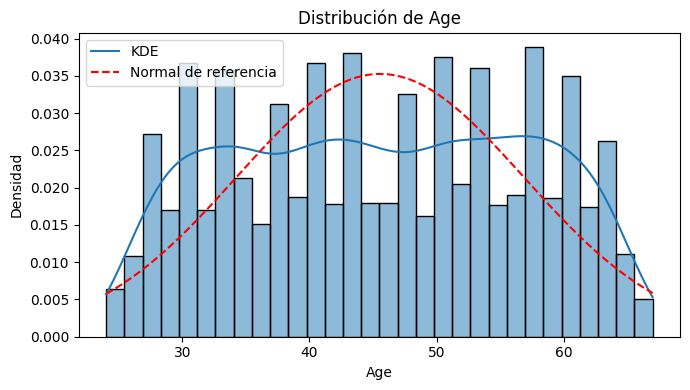

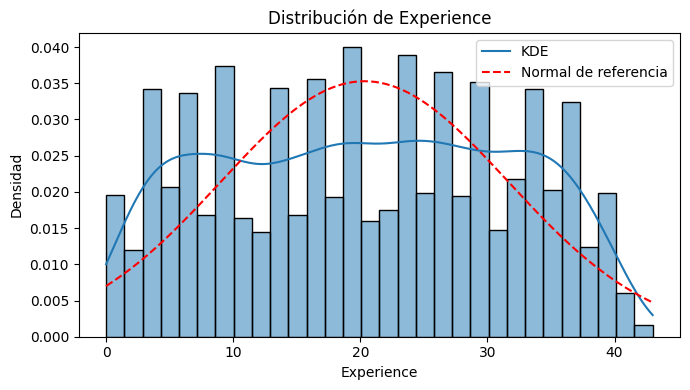

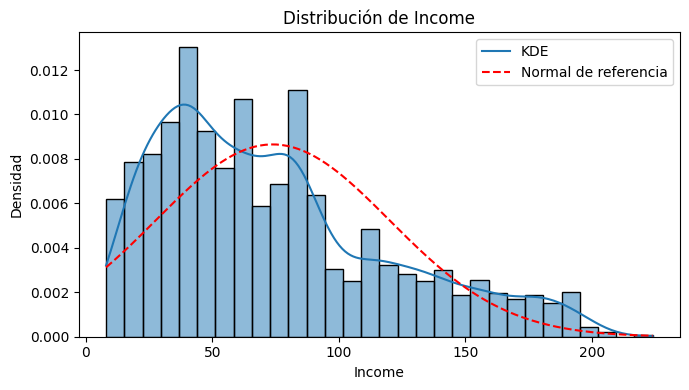

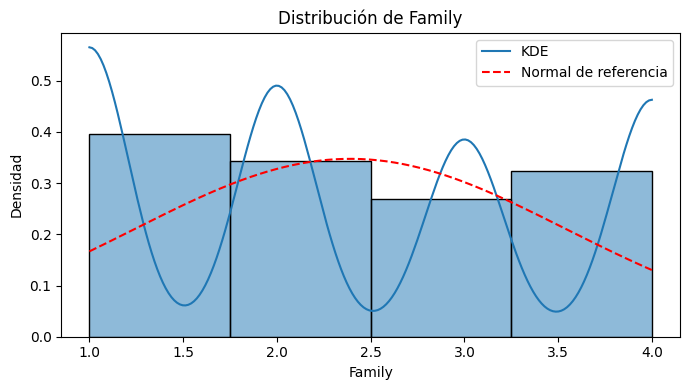

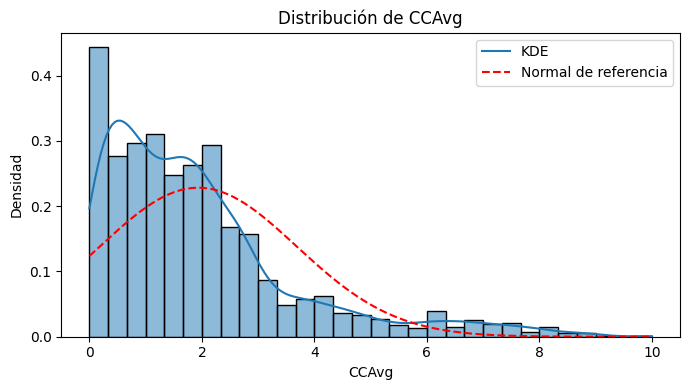

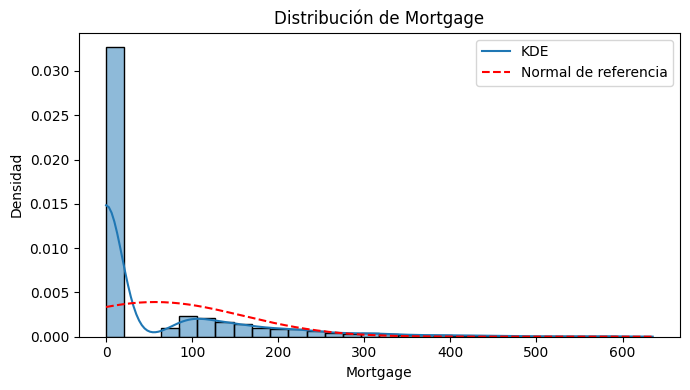

In [28]:
for columna in num_cols:
    datos = loan_df[columna]
    media = datos.mean()
    desviacion = datos.std()

    # Calcular la curva normal con la media y desviación de la variable.
    valores_x = np.linspace(datos.min(), datos.max(), 200)
    curva_normal = norm.pdf(valores_x, media, desviacion)

    numero_barras = 30
    if columna == 'Family':
        numero_barras = 4

    plt.figure(figsize=(7, 4))
    sns.histplot(datos, bins=numero_barras, stat='density',
                 kde=True, line_kws={'label': 'KDE'})
    plt.plot(valores_x, curva_normal,
             color='red', linestyle='--', label='Normal de referencia')
    plt.title('Distribución de ' + columna)
    plt.ylabel('Densidad')
    plt.legend()
    plt.tight_layout()
    plt.show()

Los histogramas coinciden con las medidas calculadas:

- **Age:** la distribución es bastante equilibrada, con una zona central amplia y más plana que la normal de referencia. Esto concuerda con asimetría casi nula y curtosis negativa.
- **Income:** predominan los ingresos bajos y medios, con una cola hacia los ingresos altos. Es consistente con la asimetría positiva moderada; su forma no es normal aunque la curtosis esté cerca de cero.
- **Mortgage:** hay una gran concentración en cero y una cola larga hacia hipotecas elevadas. Esto coincide con su fuerte asimetría positiva y su exceso de curtosis alto.

La curva normal utiliza la media y desviación estándar de cada variable y sirve únicamente como referencia. `Family` es discreta: las curvas continuas no cambian esa naturaleza.

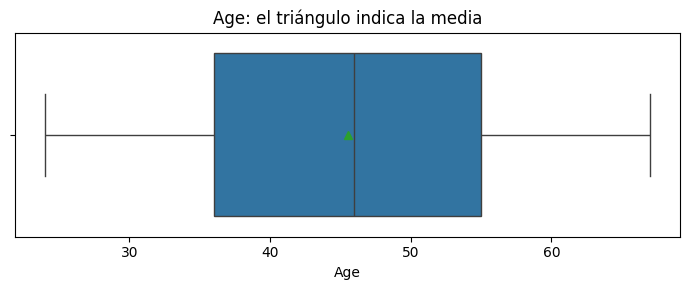

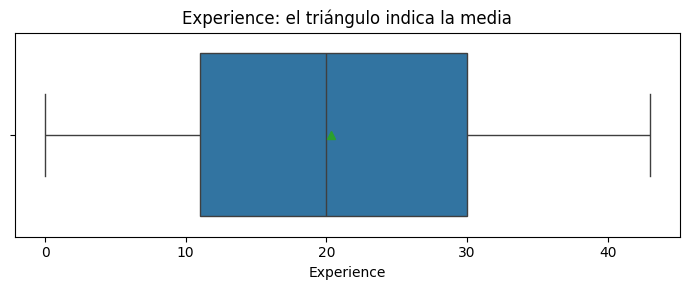

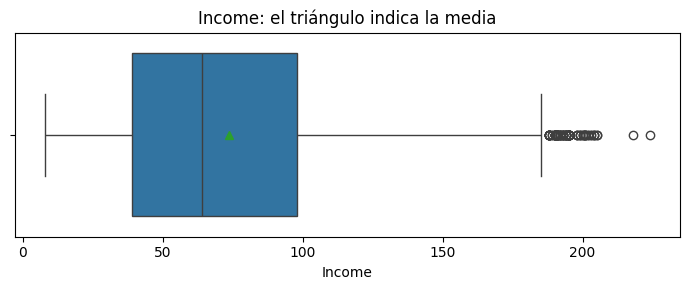

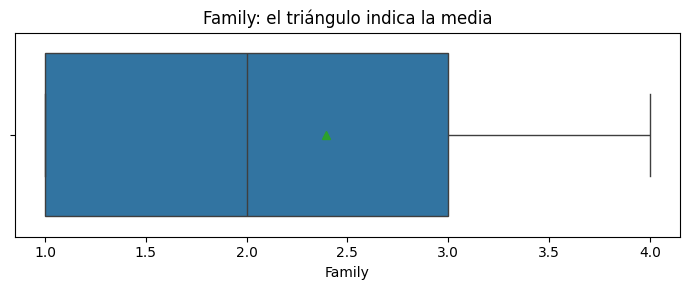

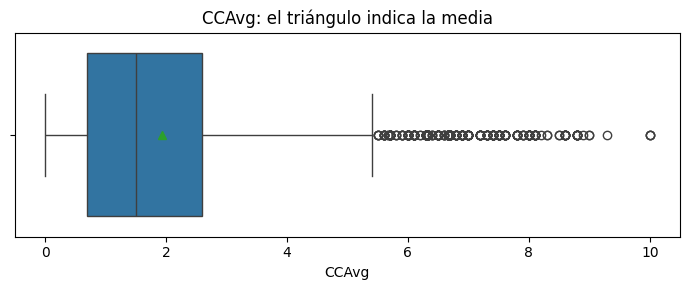

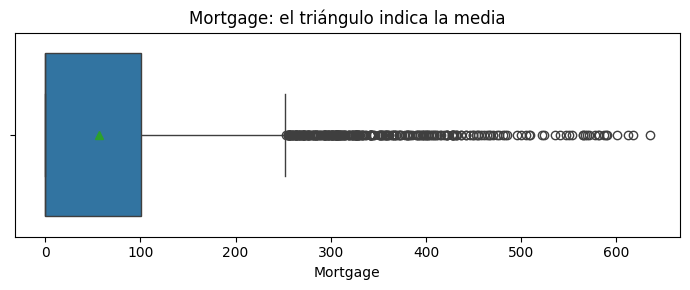

In [29]:
for columna in num_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=loan_df[columna], showmeans=True)
    plt.title(columna + ': el triángulo indica la media')
    plt.tight_layout()
    plt.show()

La línea dentro de cada caja representa la mediana y el triángulo representa la media.

| Variable | Media | Mediana | Interpretación |
|---|---:|---:|---|
| Age | 45.560 | 46.0 | Son cercanas; la media queda un poco a la izquierda y la asimetría es prácticamente nula. |
| Experience | 20.335 | 20.0 | Son cercanas; la media apenas mayor no implica un sesgo relevante. La asimetría calculada es −0.015, casi cero. |
| Income | 73.827 | 64.0 | La media mayor concuerda con la cola hacia ingresos altos. |
| Family | 2.392 | 2.0 | La media mayor es compatible con una asimetría positiva leve en un conteo discreto. |
| CCAvg | 1.936 | 1.5 | La media mayor concuerda con el sesgo hacia gastos altos. |
| Mortgage | 56.664 | 0.0 | La media supera ampliamente a la mediana por los montos elevados y la concentración de ceros. |

La posición relativa de media y mediana orienta sobre el sesgo, pero no es una regla exacta. Los puntos fuera de los bigotes indican valores atípicos según el boxplot; por sí solos no demuestran errores y se conservan.


8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [30]:
loan_df[cat_cols].describe()

,ZIP Code,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4941,4941,4941,4941,4941,4941,4941
unique,467,3,2,2,2,2,2
top,94720,1,0,0,0,1,0
freq,163,2079,4462,4426,4640,2951,3489


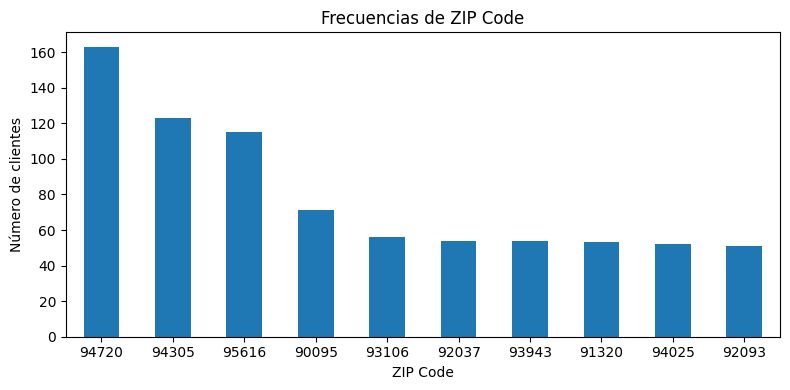

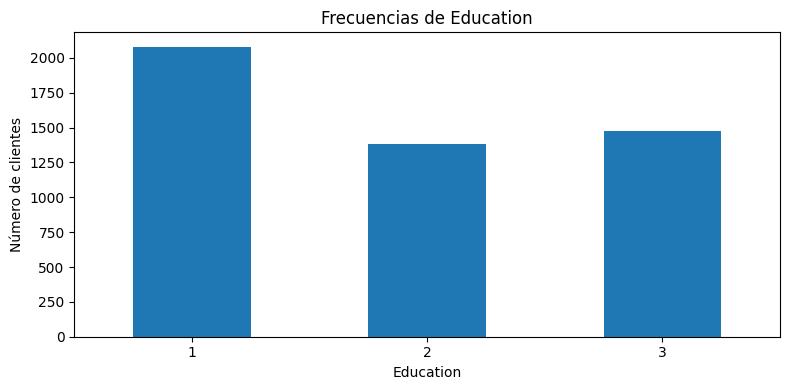

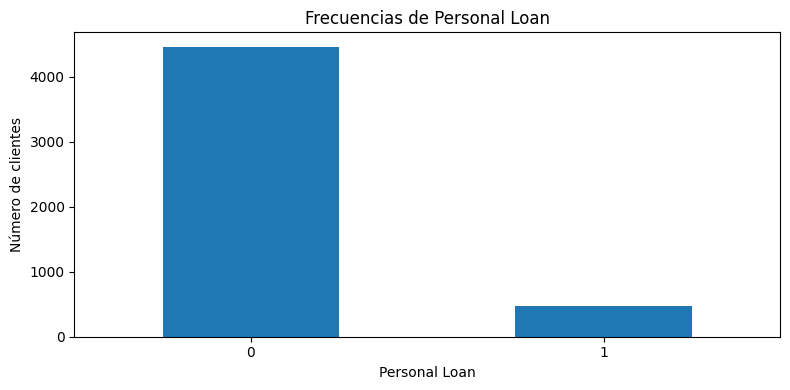

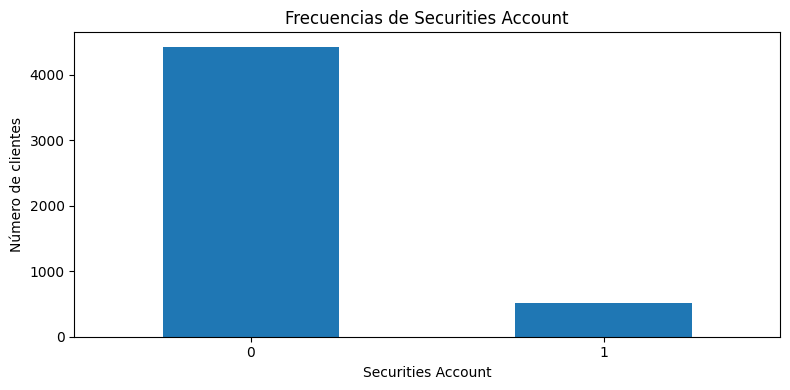

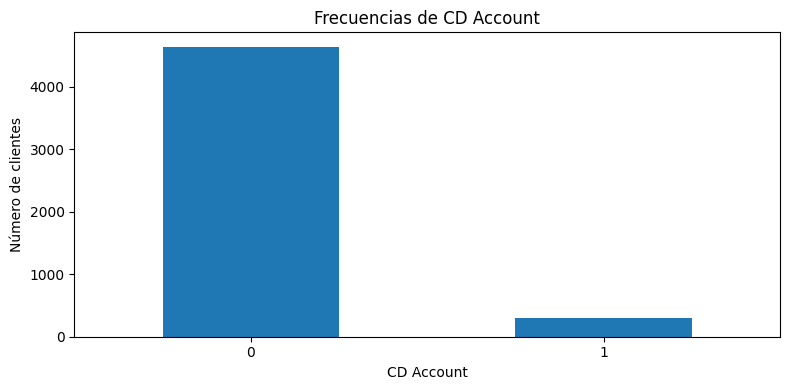

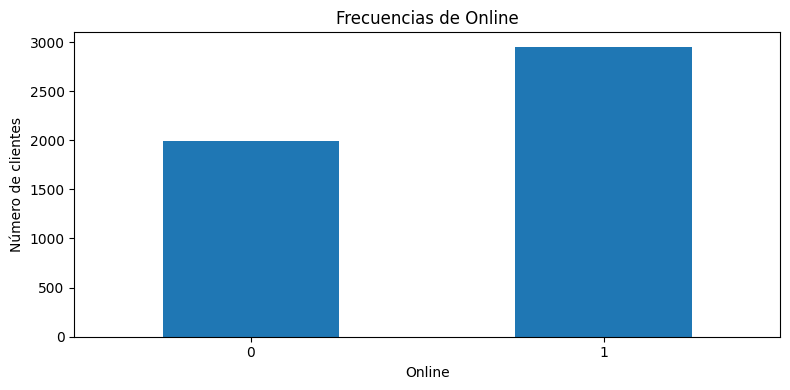

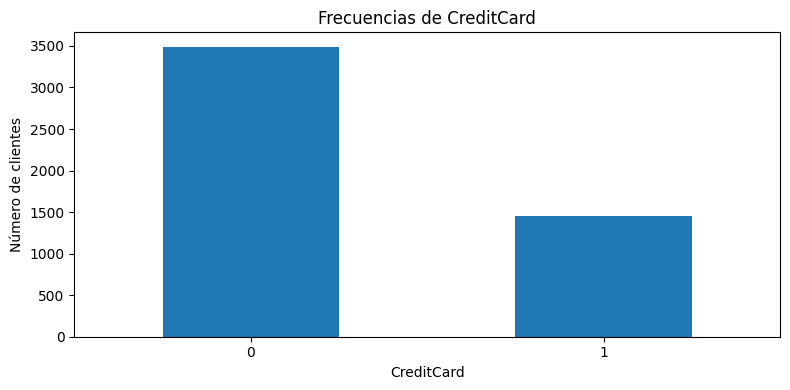

In [31]:
for columna in cat_cols:
    frecuencias = loan_df[columna].value_counts()
    if len(frecuencias) > 10:
        frecuencias = frecuencias.head(10)
    else:
        frecuencias = frecuencias.sort_index()
    frecuencias.plot.bar(figsize=(8, 4), rot=0)
    plt.title('Frecuencias de ' + columna)
    plt.xlabel(columna)
    plt.ylabel('Número de clientes')
    plt.tight_layout()
    plt.show()

En `ZIP Code`, de alta cardinalidad, se muestran los **10 códigos más frecuentes**. En las demás variables se incluyen todas las categorías. `Personal Loan` está desbalanceada: **4,462 clientes no aceptaron** el préstamo y **479 sí lo aceptaron**.

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

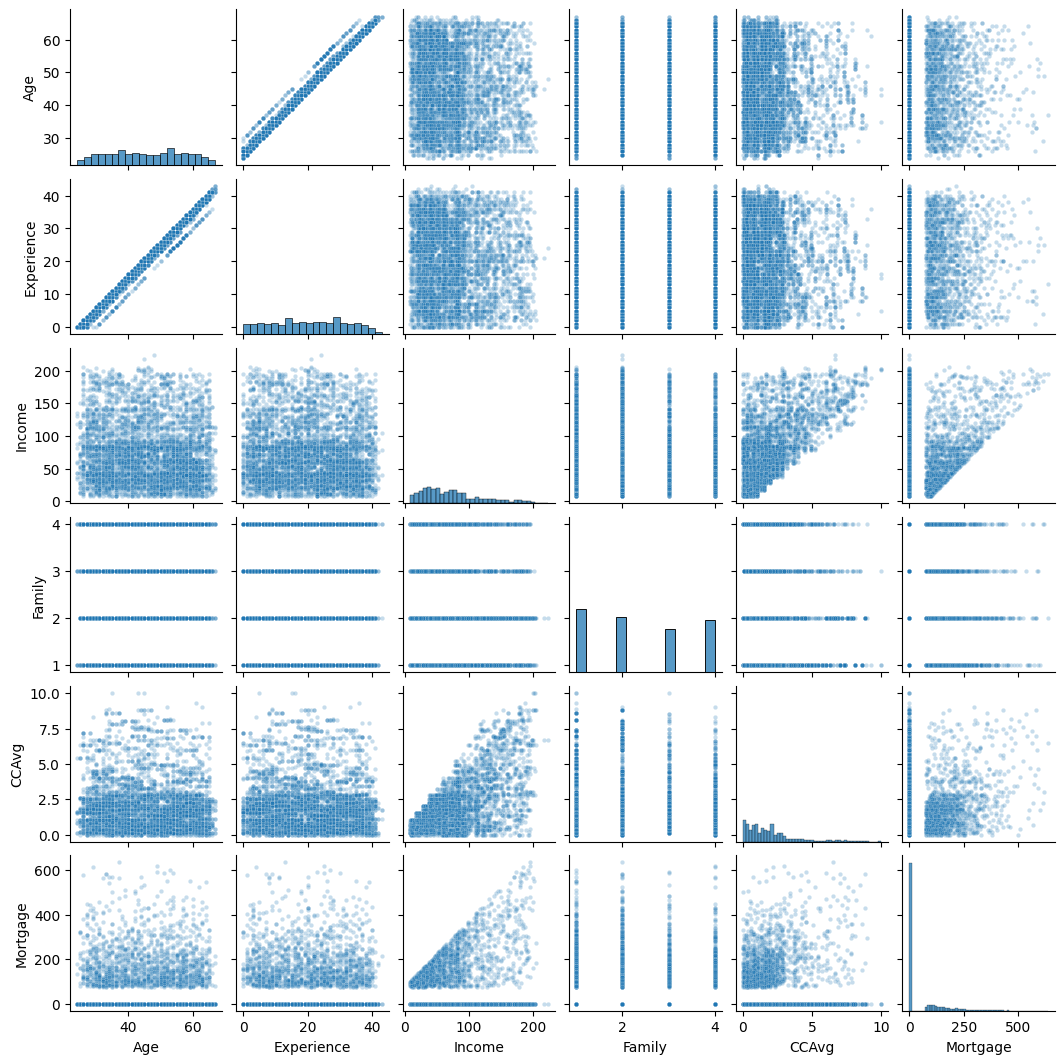

In [32]:
datos_numericos = loan_df[num_cols]

sns.pairplot(datos_numericos, diag_kind='hist', height=1.8,
             plot_kws={'alpha': 0.25, 's': 10})
plt.show()

Se selecciona el par **Income–CCAvg**. La nube de puntos muestra una tendencia ascendente: los clientes con mayores ingresos tienden a tener un mayor gasto mensual con tarjeta. Existe dispersión, por lo que la relación no es perfecta. También se observa una relación casi lineal entre `Age` y `Experience`, coherente con el aumento de la experiencia laboral con la edad.

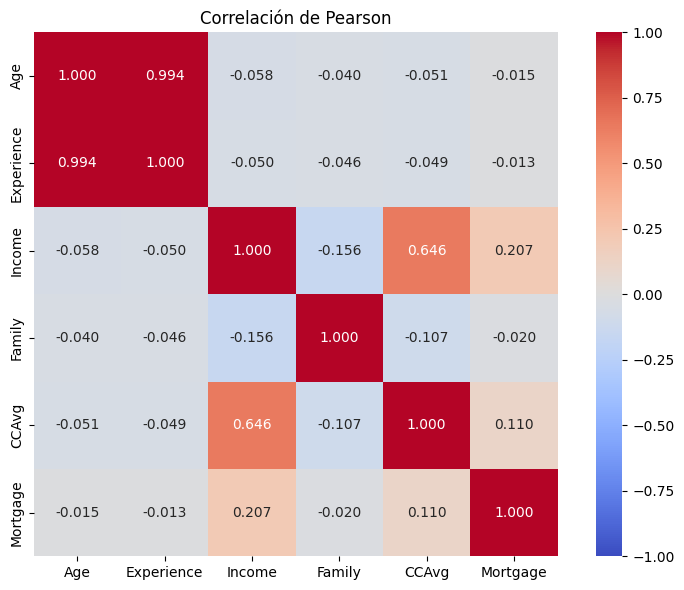

In [33]:
correlaciones = datos_numericos.corr(method='pearson')
plt.figure(figsize=(8, 6))
sns.heatmap(correlaciones, annot=True, fmt='.3f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True)
plt.title('Correlación de Pearson')
plt.tight_layout()
plt.show()

Para **Income–CCAvg**, la correlación de Pearson es **r = 0.646**: positiva y de magnitud moderada a alta. Sí corresponde con la tendencia ascendente y la dispersión observadas. Para `Age–Experience`, **r = 0.994** confirma la relación lineal positiva casi perfecta. Estas asociaciones no demuestran causalidad.

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


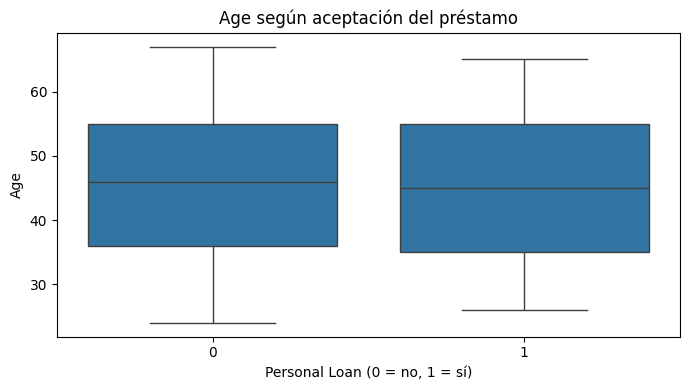

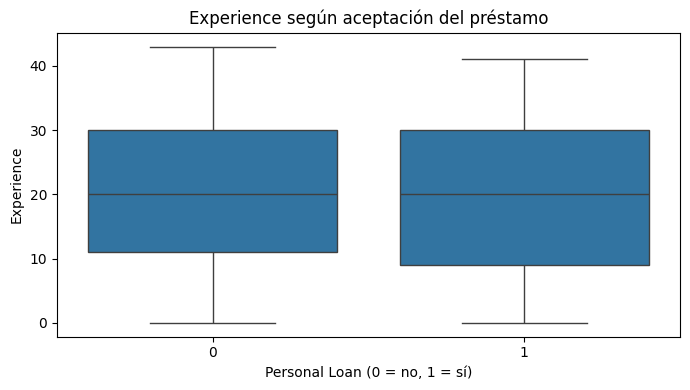

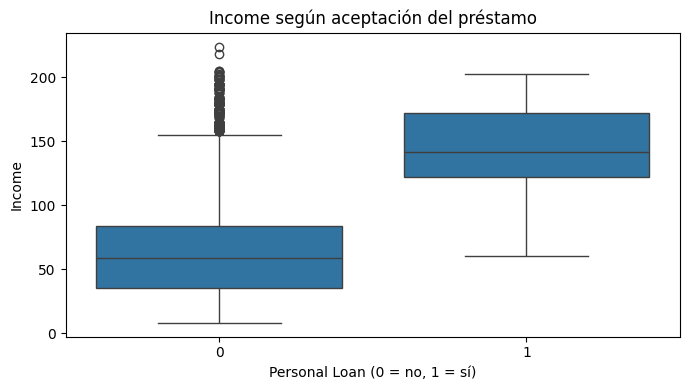

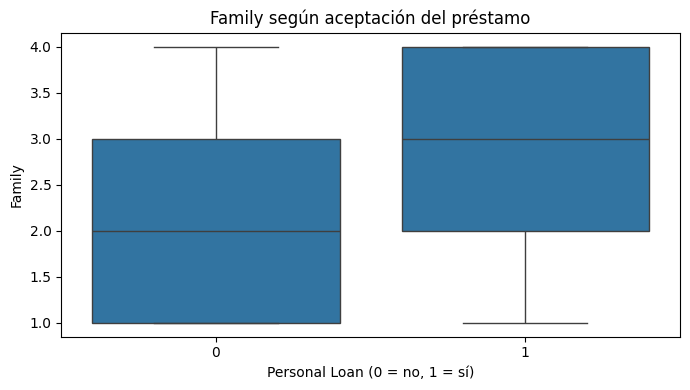

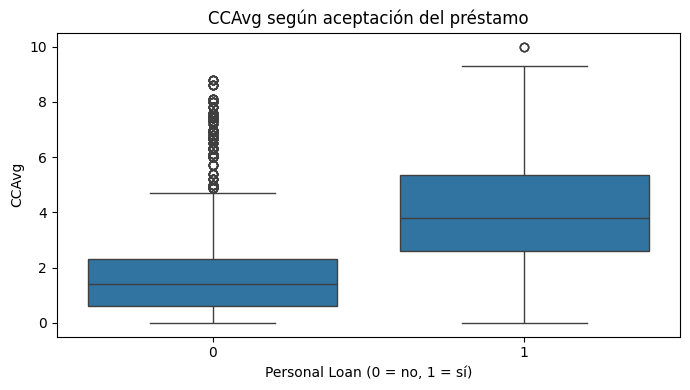

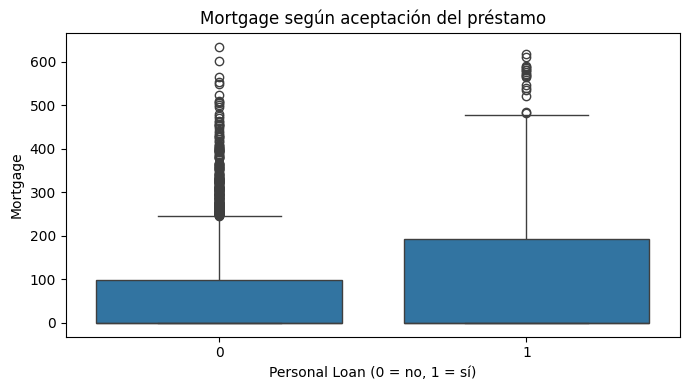

In [34]:
for columna in num_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=loan_df, x='Personal Loan', y=columna)
    plt.title(columna + ' según aceptación del préstamo')
    plt.xlabel('Personal Loan (0 = no, 1 = sí)')
    plt.tight_layout()
    plt.show()

**Variables numéricas:** la mayor diferencia se observa en `Income`. La mediana del ingreso anual es **142 mil USD** entre quienes aceptaron el préstamo y **59 mil USD** entre quienes no lo aceptaron. En `CCAvg`, las medianas son **3.8** y **1.4 mil USD mensuales**, respectivamente. Esto muestra una asociación de la aceptación con ingresos y gasto con tarjeta más altos.

En `Family`, la mediana es 3 para quienes aceptaron y 2 para quienes no. `Age` y `Experience` presentan distribuciones similares entre grupos: las medianas de edad son 45 y 46 años, respectivamente, y la experiencia mediana es 20 años en ambos. `Mortgage` tiene mediana cero en ambos grupos, aunque entre quienes aceptaron se observan una mayor dispersión y montos superiores.

Porcentajes de aceptación según Education


Personal Loan,0,1
Education,,
1,95.53,4.47
2,86.93,13.07
3,86.12,13.88


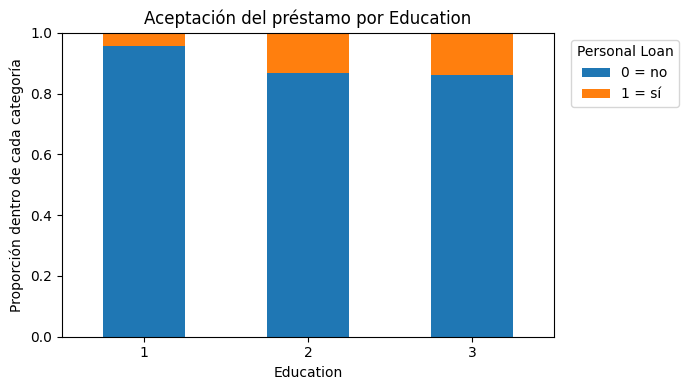

Porcentajes de aceptación según Securities Account


Personal Loan,0,1
Securities Account,,
0,90.53,9.47
1,88.35,11.65


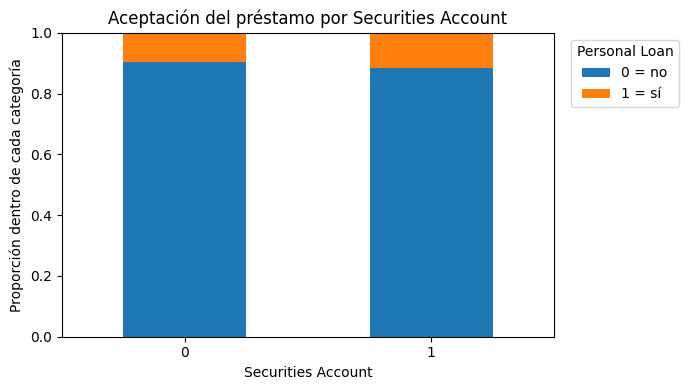

Porcentajes de aceptación según CD Account


Personal Loan,0,1
CD Account,,
0,92.69,7.31
1,53.49,46.51


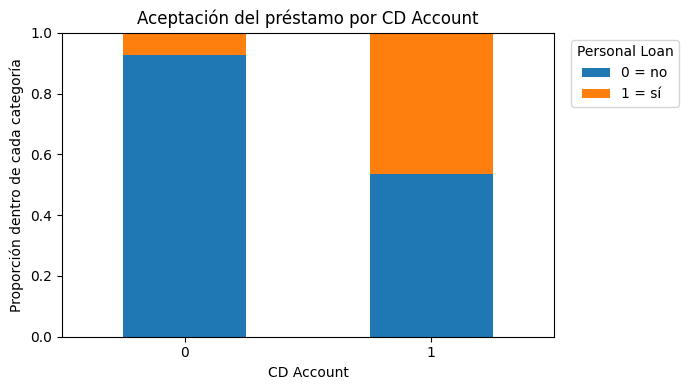

Porcentajes de aceptación según Online


Personal Loan,0,1
Online,,
0,90.55,9.45
1,90.14,9.86


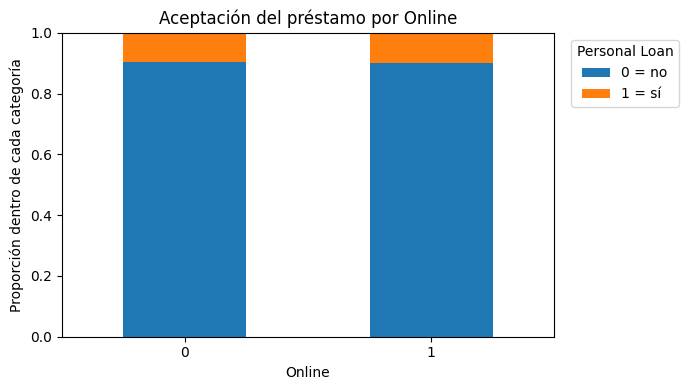

Porcentajes de aceptación según CreditCard


Personal Loan,0,1
CreditCard,,
0,90.37,9.63
1,90.15,9.85


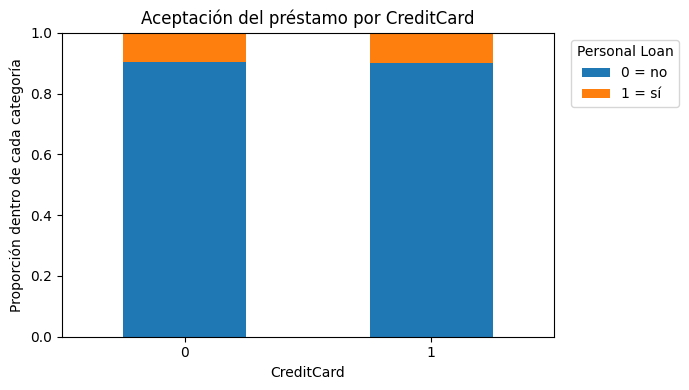

In [36]:
categoricas_comparar = cat_cols.copy()
categoricas_comparar.remove('ZIP Code')
categoricas_comparar.remove('Personal Loan')

for columna in categoricas_comparar:
    # Cada fila suma 1: muestra proporciones dentro de una categoría.
    proporciones = pd.crosstab(loan_df[columna], loan_df['Personal Loan'],
                               normalize='index')
    # Convertir las proporciones a porcentajes y mostrarlos.
    porcentajes = (proporciones * 100).round(2)
    print('Porcentajes de aceptación según', columna)
    display(porcentajes)

    proporciones.plot.bar(stacked=True, figsize=(7, 4), rot=0)
    plt.title('Aceptación del préstamo por ' + columna)
    plt.ylabel('Proporción dentro de cada categoría')
    plt.ylim(0, 1)
    plt.legend(title='Personal Loan', labels=['0 = no', '1 = sí'],
               bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

**Variables categóricas:** cada barra suma 1 y representa la distribución de `Personal Loan` dentro de una categoría de la variable explicativa. Se excluyen `ZIP Code`, como se solicita, y la propia variable de salida para no compararla consigo misma.

- **CD Account:** aceptó el préstamo el **46.51 %** de quienes tienen certificado de depósito, frente al **7.31 %** de quienes no lo tienen. Es la diferencia más marcada entre las variables categóricas analizadas.
- **Education:** la aceptación es **4.47 %** para el nivel 1, **13.07 %** para el nivel 2 y **13.88 %** para el nivel 3.
- **Securities Account:** la aceptación es **11.65 %** con cuenta de valores y **9.47 %** sin ella.
- **Online:** las proporciones son parecidas: **9.86 %** entre quienes usan banca en línea y **9.45 %** entre quienes no.
- **CreditCard:** también hay poca diferencia: **9.85 %** para titulares y **9.63 %** para no titulares.

Los resultados describen asociaciones dentro de este conjunto de datos, sin establecer relaciones de causa y efecto.

---

**Declaración de uso de IA**

OpenAI. (2026). *Codex (basado en GPT-6)* [Modelo de lenguaje grande], utilizado para generar y depurar el código. https://openai.com/codex/

---
